# Qwen-27B Net-Torque-to-Answer Fracture Rescue

The preceding 900-scene audit found a large and unusually clean error class: Qwen-27B often gave the wrong tipping outcome even when the signed net torque was both recoverable from the outcome-prompt hidden state and answered correctly in a separate net-torque question.

[实验设置与运行说明](../../../docs/experiment_notes/11_handoff_development_and_matching/e74e00644345abb9.md)


In [ ]:
# Notebook utilities: support/visualtorque_checks.py
import base64 as _vt_base64, gzip as _vt_gzip, sys as _vt_sys, types as _vt_types
_vt_source = _vt_gzip.decompress(_vt_base64.b64decode("H4sIAAAAAAACCo1Y647bthL+76dgtziwtLGVTZAGqFs3J8BJkABJESCLoqjXFWiJsnmWElWS2qx7Afo0fbA+SWd4kSnJ23Z/JBLnPvPNcOSLi4vXXDBSHFhxqwltStJIw3ZS3pKS61bQI+kMF9xwpjPyrSS1LJkgUhF23zLFa9YYUrKWNSVrCmS6uLiY8bqVypCqawojpdDh4ED1QfBdeFUsPOmjnlVK1uRgapG1VGmmiKe9uX7/7oM9cSwtNagkkD/A62w2K1lFKgglRxsJ8qSrGYG/ku+ZNmQdjGf6QJ9+8TxJLfUTNwerwolkEiJJ5mo3TwnVINKUgjk9+FdB3MWha24Jbwg3TCWC1ruSrjxnphgtkydXT5+RS4L/pQuym8/Tk4aTR1nXltSwxOpzzihmOtUE+oHduydw1cXnPM8xzDhCLzZ35NWcPBpnYiqf7455Q2uW2JepstjUiQX0AAFyGZFnljw9diZ3R8M0UhMIlj7s8Kg4lvlMBhqpair4z9ZgckdFx0Z+G+WPoRa1vGOtYhW/T3pbqCl/8/LjG3BXsayQdYsxqnny4uvPNi+XP9Dlz1fLL/NtmrxYbeCJLquXy9fbX54/++3X+P3Z1W/AMhQB7fn1q++v8/dv37/6CBaSuWH35jH0EW/mC+LeEOP9S03VbSk/NfMQInpEC5MjNcF/FjY5TK+/lU2IFprs4wHQz5rQpqz0bAsiW8NlQ4U4klvGWt7sCYVY75jSfAfNLqC7u9Y2qoUjGFUMdBQsqakpDhFcbSohDnue7ZXsWt84+KfRBaBars3qydUWKjn/8/c/sKLucPl8te35eeV9JFzjnCEY0bA3eOW1QoN5XhxK7nFjSVvymTc5FI1QYKkD4lDBesTRgx6oMZosUDLd7RKfoAXBimCpCkG1Jvl33Ob0Got1GlRh9EBm85w33OR5opmonHgoaJRn3cEwTdKs5y5kA/UyeXGgChCs16+p0CxKPWjLnDL7GGpvX0CogbaBMGNzC7LZDuVlVWlmkG9zdZ6UgTyM9qTO8N/UDsAaawOtU/GmtDNwfoPYtokZOSiQTgUYwErP+qS4aZlrQ5UxdB9yQ/cLQo1RcWYAEHCOJqGHC8Vbg62jzVGw8VwdmQSxiUWIYmBvami9Huj5Wwtng8LR5Q1EIy9g+0HVDnH9kSthCUYG8wA1DiqextqDEPQHMg4NCN4AfAspurohPsg9M63UUUfbILEqgcPjYIPSZEmeYIc7HdPEeNhltMV1IEmsooXX94gIuFltRhbB0XQ883Ay/t3Me8foHbMQ4bvOIKTBr1uEvUUGPiAw3MzgNd0zmwhAjwH1/cTz+8V62L6D1oz4soqxMnF9H50WQmrmU4dt4aOFyBd+bNo2wakL4kHIpSgCBer1jbpZWR3bMDzhf3sMKv0Q9WMJT0eZC9fIg9n7nLyDVAFQteENxQtCg7oa7iXSaQo5WIC/hehKvC5sVomRVs8S94SSgGe8AlM6C1mwkwMGAdw/3OANerO9STY/ptvLm/TXgzGtfrF6/Hjz443++pvtozTMiMEKMM/+L3mD6TGIYE7+Q54SBqNuiPvW5nYM+egPK8AXxOlpoApdDT1mmJXUE6DZ/LpFYUFq2GLXw4t6mj+7y0LWoo5EtKLTKI9zI7rdhyGE4kyZ+9t/GvPMNzUgtAFcNEXvr+DaRAj6nDS7CvciQ+ASqTmUhZK6E7i2Q9PCRoQlhWLu8EUqrCV2CFRU0WPW68FC2IkTiuL2qOiS1KAU6CEViZOY1sUX1wk4eKArOsF1BNCs19cKNGN0XilMLG/e5uF0O3tVvUmfAm/xfH4g4jTWM+oUKICfo9Mq9zGWvHDT9tTgtnKArWjDG8z2QHc6xtMdzzbIso0Q5GAYEx0ahykdpPO0evzPLX4fDXx01M5cfsd1RwUU+acOr1ekgDnM9uyhjcRxxbsIzvKTsHs4iX9ScH1F28wDkpnjm2yz6QQmeC/4rWpgw0HGGbLP6fBDzKIb8m1pZ+5p5wBSI82V6OCjCOmRtrD+xe47xjROG9yWePX0mcO5ONXiuZJYm+f1SMxhoYNiHjxRJ5dU7eHuury8/YRPYeJAjCjmdx9Tys7vPiVTKl5++lr1to86mIyXD8cW7d7hg/8k6N2dn0MSGHdb6DjZI6OLETa91n4I4/chbEC5/3JJYP4xBcBn5iDL3GmAPHT424K3JRXfw7UlohjPSdlODoOzl4GAbbCQz17Y0yaRep/OhOoXNPv+3/6XDUAZbXWvL+3h0nY7mNOHB2rrXcSTYTLxBL8bB9MKD2FDh8XJats8WW1PhYU+qfp0IVacoaFadxbmmnflDMcmKIqnlPVhTJ+0cUjBJGKXMp+P7Gy6w4yK4XSuvl5JAJId/EL0QIKRKcRoZXxtsTb9VUs24viVuyDAWfzFwm2NxYGLctkqWTAYskJC1sDIEW4gIfoF0n6lgq0ArWidU8dh5u1PVm8/HCGKJvxkBSjMeWuPTmW8L1hryFvL8Uopqc59HzhURh/g6MQ6Vpik/+DhRNFkHDkN4y616jL/lkMloHd8PXAq4V05/xeSBygCsNvhnLu1xX4yoY7wChid92EMxhNqemA65aj5TN8667CHN7C6KraH5Qm/WVvFctU1eQFUkBonIR3JP2gxhq5PrX3/C0ov0eJaFQAA"))
_vt_checks = _vt_types.ModuleType("visualtorque_checks")
exec(compile(_vt_source, "<visualtorque_checks>", "exec"), _vt_checks.__dict__)
_vt_sys.modules["visualtorque_checks"] = _vt_checks
_vt_checks.install_display()
del _vt_source


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Frozen support and causal protocol


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import json
import os
import signal
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)

ANALYSIS_STACK = {
    'numpy': '2.5.1',
    'scipy': '1.18.0',
    'pandas': '3.0.5',
    'matplotlib': '3.11.1',
    'scikit-learn': '1.9.0',
    'tqdm': '4.67.1',
}
ENV_MARKER = Path('/content/visualtorque_inference_analysis_stack_v3.json')
probe_code = '''
import json
import matplotlib
import numpy
import pandas
import scipy
import sklearn
import tqdm
print(json.dumps({
    'numpy': numpy.__version__,
    'scipy': scipy.__version__,
    'pandas': pandas.__version__,
    'matplotlib': matplotlib.__version__,
    'scikit-learn': sklearn.__version__,
    'tqdm': tqdm.__version__,
}, sort_keys=True))
'''

def fresh_process_probe():
    return subprocess.run(
        [sys.executable, '-c', probe_code],
        text=True, capture_output=True, check=False,
    )

try:
    marker = json.loads(ENV_MARKER.read_text(encoding='utf-8'))
except (FileNotFoundError, json.JSONDecodeError):
    marker = None
probe = fresh_process_probe()
stack_ready = (
    marker == ANALYSIS_STACK
    and probe.returncode == 0
    and json.loads(probe.stdout.strip().splitlines()[-1]) == ANALYSIS_STACK
)
if not stack_ready:
    cell_stage('Repairing the pinned binary analysis stack')
    packages = [
        f'{name}=={version}' for name, version in ANALYSIS_STACK.items()
    ]
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install',
        '--no-cache-dir', '--force-reinstall', '--only-binary=:all:',
        *packages,
    ])
    repaired = fresh_process_probe()
    if repaired.returncode != 0:
        raise RuntimeError(
            'The repaired stack still fails in a fresh Python process.\n'
            + repaired.stderr[-4000:]
        )
    repaired_versions = json.loads(
        repaired.stdout.strip().splitlines()[-1]
    )
    assert repaired_versions == ANALYSIS_STACK, repaired_versions
    ENV_MARKER.write_text(
        json.dumps(ANALYSIS_STACK, sort_keys=True), encoding='utf-8'
    )
    print(
        '\nPinned binary packages were repaired. Colab will restart once. '
        'After it reconnects, choose Runtime > Run all. This is expected.',
        flush=True,
    )
    os.kill(os.getpid(), signal.SIGKILL)

cell_stage('Installing pinned inference dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34',
])
verified = fresh_process_probe()
assert verified.returncode == 0, verified.stderr[-4000:]
assert json.loads(verified.stdout.strip().splitlines()[-1]) == ANALYSIS_STACK

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('numpy / scipy / sklearn:',
      np.__version__, scipy.__version__, sklearn.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
numpy / scipy / sklearn: 2.5.1 1.18.0 1.9.0
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify GPU and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify GPU and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the stagewise fracture-rescue protocol
cell_stage('Freezing prior audit, sites, directions, strengths, and decisions')
import hashlib
import json
from datetime import datetime, timezone

MODEL_KEY = 'qwen27b'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
NET_LAYER = 32
SEMANTIC_LAYER = 49
LABEL_LAYER = 55
CAPTURE_LAYERS = (NET_LAYER, SEMANTIC_LAYER, LABEL_LAYER)
SITE_SCOPE = 'final_prompt_token'

SEED = 20261030
DIRECTION_SEED = 20260901
LABELS = ('A', 'B', 'C')
MAPPING_VARIANTS = ('forward', 'reverse')
DONOR_TASKS = ('weight_more', 'weight_less')
QUESTION_KINDS = (
    'outcome', 'left_units', 'right_units', 'left_distance',
    'right_distance', 'left_torque', 'right_torque', 'net_torque',
)
ALPHAS = (0.5, 1.0, 2.0)
CONDITIONS = (
    'l32_net_exact', 'l32_net_reverse', 'l32_net_random',
    'l49_semantic_exact', 'l49_semantic_reverse', 'l49_semantic_random',
    'l55_code_exact', 'l55_code_stale', 'l55_code_random',
)
TARGET_CANDIDATES = 64
MIN_RUNTIME_TARGETS = 16
PATCH_CONDITION_BATCH_SIZE = 1
BOOTSTRAP_REPLICATES = 10000
ALPHA_LEVEL = 0.05
PRIMARY_ALPHA = 1.0
ERROR_SESOI_LOGODDS = 0.20
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
NORM_RELATIVE_TOLERANCE = 0.02

AUDIT_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_error_conditioned_physical_state_audit_v1'
)
AUDIT_RUN_PATH = AUDIT_ROOT / 'RUN_COMPLETE.json'
AUDIT_PROTOCOL_PATH = AUDIT_ROOT / 'frozen_protocol.json'
AUDIT_OUTCOME_MANIFEST_PATH = AUDIT_ROOT / 'outcome_prompt_manifest.jsonl'
AUDIT_CONFIRMATION_PATH = AUDIT_ROOT / 'confirmation_scene_manifest.jsonl'
AUDIT_PROBE_LOCK_PATH = AUDIT_ROOT / 'frozen_probe_selection.json'
AUDIT_PROBE_PREDICTIONS_PATH = (
    AUDIT_ROOT / 'analysis' / 'probe_test_predictions.csv'
)
AUDIT_TASK_SCORES_PATH = (
    AUDIT_ROOT / 'analysis' / 'intermediate_task_scores.csv'
)
AUDIT_FRACTURE_PATH = AUDIT_ROOT / 'analysis' / 'scene_fracture_map.csv'
AUDIT_OUTCOME_SHARD_DIR = AUDIT_ROOT / 'outcome_capture_shards'

DEPTH_ROOT = PROJECT_ROOT / 'results' / 'semantic_label_depth_localization_v1'
DEPTH_SUPPORT_PATH = DEPTH_ROOT / 'depth_support.jsonl'
DEPTH_DECISION_PATH = (
    DEPTH_ROOT / 'models' / MODEL_SLUG / 'analysis' / 'depth_decision.json'
)
INVERSE_SCENE_DIR = (
    PROJECT_ROOT / 'results' / 'inverse_query_weight_route_specificity_v1'
    / 'rendered_scenes'
)

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_nettorque_to_answer_fracture_rescue_v1'
)
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_protocol.json'
CANDIDATE_MANIFEST_PATH = OUTPUT_ROOT / 'recalibrated_candidates.jsonl'
CANDIDATE_LOCK_PATH = OUTPUT_ROOT / 'candidate_lock.json'
RUNTIME_REPLAY_PATH = OUTPUT_ROOT / 'runtime_mapping_replay.jsonl'
RUNTIME_MANIFEST_PATH = OUTPUT_ROOT / 'runtime_stable_targets.jsonl'
RUNTIME_LOCK_PATH = OUTPUT_ROOT / 'runtime_target_lock.json'
SHARD_DIR = OUTPUT_ROOT / 'target_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (OUTPUT_ROOT, SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

from visualtorque_checks import sha256_file

def stable_key(value, seed=SEED):
    return hashlib.sha256(f'{seed}:{value!r}'.encode('utf-8')).hexdigest()

def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if torch.is_tensor(value) and value.numel() == 1:
        return value.item()
    raise TypeError(f'Object of type {type(value).__name__} is not JSON serializable')

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(
            value, indent=2, ensure_ascii=False, default=json_default
        ) + '\n', encoding='utf-8',
    )
    temporary.replace(path)

def write_jsonl_atomic(path, rows):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, sort_keys=True, default=json_default
            ) + '\n')
    temporary.replace(path)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

required_inputs = (
    AUDIT_RUN_PATH, AUDIT_PROTOCOL_PATH, AUDIT_OUTCOME_MANIFEST_PATH,
    AUDIT_CONFIRMATION_PATH, AUDIT_PROBE_LOCK_PATH,
    AUDIT_PROBE_PREDICTIONS_PATH, AUDIT_TASK_SCORES_PATH,
    AUDIT_FRACTURE_PATH,
    DEPTH_SUPPORT_PATH, DEPTH_DECISION_PATH, INVERSE_SCENE_DIR,
)
for required in required_inputs:
    assert Path(required).exists(), f'Missing prerequisite: {required}'

protocol_identity = {
    'schema_version': 'nettorque-to-answer-fracture-rescue-1.0',
    'analysis_status': 'confirmatory_on_preexisting_error_diagnostics',
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'sites': {
        'net_torque': [NET_LAYER, SITE_SCOPE],
        'physical_semantic': [SEMANTIC_LAYER, SITE_SCOPE],
        'answer_code': [LABEL_LAYER, SITE_SCOPE],
    },
    'site_selection': 'frozen before the 900-scene error audit',
    'target_selection': (
        'preexisting probe_test outcome errors with binary exact/wrong sides, '
        'correct direct net-torque sign, and correct held-out net-torque '
        'readout sign; no current intervention output is used'
    ),
    'side_torque_boundary': (
        'exact side-torque magnitude is not used to select this downstream '
        'cohort; the direct and held-out net-torque sign tests are primary'
    ),
    'mapping_stability': (
        'retain only targets predicting the same wrong physical side under '
        'two mappings that swap exact and wrong answer letters'
    ),
    'alphas': list(ALPHAS),
    'conditions': list(CONDITIONS),
    'primary_alpha': PRIMARY_ALPHA,
    'primary_coordinate': (
        'within-target exact-versus-wrong candidate log-odds shift, averaged '
        'over both mappings'
    ),
    'primary_decision_tree': [
        'L32 exact-minus-random positive -> weak net signal is sufficient',
        'L32 fails and L49 exact-minus-random positive -> net-to-semantic fracture',
        'L49 fails and L55 exact beats stale/random -> semantic-to-label fracture',
        'otherwise unresolved downstream fracture',
    ],
    'bootstrap_unit': 'unique physical target scene',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'seed': SEED,
}
canonical_protocol_identity = json.loads(json.dumps(
    protocol_identity, sort_keys=True
))
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == canonical_protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': canonical_protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Stagewise sites:', CAPTURE_LAYERS)
print('Output:', OUTPUT_ROOT)


Lock the stagewise fracture-rescue protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f…dd9801
Stagewise sites: (32, 49, 55)
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_nettorque_to_answer_fracture_rescue_v1


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/17 Freeze the pre-intervention target support
cell_stage('Loading the prior fracture map and disjoint direction support')
from collections import Counter, defaultdict
import shutil

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')

def is_single_stack_scene(row):
    stacks = row.get('stacks', [])
    counts = Counter(str(stack.get('side')) for stack in stacks)
    return bool(
        str(row.get('metadata', {}).get('family', '')) == 'single_stack'
        and str(row.get('scene_id', '')).startswith('single_')
        and len(stacks) == 2 and counts == {'left': 1, 'right': 1}
    )

single_scenes = [row for row in scene_records if is_single_stack_scene(row)]
assert len(single_scenes) == 900, len(single_scenes)
scene_by_id = {str(row['scene_id']): row for row in single_scenes}

def sign(value):
    return int(value > 0) - int(value < 0)

def scene_features(scene):
    left = next(stack for stack in scene['stacks'] if stack['side'] == 'left')
    right = next(stack for stack in scene['stacks'] if stack['side'] == 'right')
    derived = scene['derived']
    left_units, right_units = int(left['units']), int(right['units'])
    left_distance, right_distance = int(left['distance']), int(right['distance'])
    net_torque = int(derived['net_torque'])
    torque_sign = sign(net_torque)
    weight_cue = sign(left_units - right_units)
    distance_cue = sign(left_distance - right_distance)
    if torque_sign and weight_cue != torque_sign and distance_cue == torque_sign:
        diagnostic_cell = 'weight_conflict'
    elif torque_sign and distance_cue != torque_sign and weight_cue == torque_sign:
        diagnostic_cell = 'distance_conflict'
    elif torque_sign and weight_cue == torque_sign and distance_cue == torque_sign:
        diagnostic_cell = 'both_cues_aligned'
    else:
        diagnostic_cell = 'mixed_or_balanced'
    return {
        'left_units': left_units, 'right_units': right_units,
        'left_distance': left_distance, 'right_distance': right_distance,
        'left_torque': int(derived['left_torque']),
        'right_torque': int(derived['right_torque']),
        'net_torque': net_torque, 'outcome': str(derived['outcome']),
        'weight_cue': weight_cue, 'distance_cue': distance_cue,
        'diagnostic_cell': diagnostic_cell,
    }

physical_by_scene = {
    scene_id: scene_features(scene) for scene_id, scene in scene_by_id.items()
}

# Reconstruct the exact counterbalanced outcome examples used by the audit.
loader_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR, output_dir=OUTPUT_ROOT / '_unused_loader',
    model_id=MODEL_ID, model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,), question_kinds=QUESTION_KINDS,
    splits=('probe_train', 'probe_dev', 'probe_test'), batch_size=1,
    generation_every=0, seed=SEED,
)
all_examples = tuple(load_behavior_examples(loader_config))
examples_by_scene_kind = defaultdict(list)
for example in all_examples:
    scene_id = str(example.scene_id)
    if scene_id in scene_by_id:
        examples_by_scene_kind[(scene_id, example.question_kind)].append(example)

prior_outcome_manifest = read_jsonl(AUDIT_OUTCOME_MANIFEST_PATH)
outcome_example_by_scene = {}
for row in prior_outcome_manifest:
    scene_id = str(row['scene_id'])
    candidates = examples_by_scene_kind[(scene_id, 'outcome')]
    outcome_example_by_scene[scene_id] = next(
        example for example in candidates if str(example.variant) == str(row['variant'])
    )

direction_support = read_jsonl(DEPTH_SUPPORT_PATH)
EXPECTED_DIRECTION_FAMILIES = len(direction_support)

def canonical_signature(stacks):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in stacks
    ))

direction_signatures = {
    canonical_signature(role['stacks'])
    for row in direction_support for role in row['roles'].values()
}

fracture_frame = pd.read_csv(AUDIT_FRACTURE_PATH)
confirmation_frame = pd.DataFrame(read_jsonl(AUDIT_CONFIRMATION_PATH))
prior_candidates = fracture_frame[
    (fracture_frame['cohort'] == 'outcome_error')
    & (fracture_frame['candidate_fracture'] == 'net_torque_to_outcome')
    & fracture_frame['net_torque_task_pass'].astype(bool)
    & fracture_frame['net_torque_probe_pass'].astype(bool)
].copy()
assert len(prior_candidates) == 64, (
    'The preceding completed audit is expected to contribute 64 frozen '
    'net-torque-to-outcome candidates.', len(prior_candidates)
)

candidate_rows = []
for record in prior_candidates.to_dict('records'):
    scene_id = str(record['scene_id'])
    features = physical_by_scene[scene_id]
    exact = str(features['outcome'])
    wrong = str(record['outcome_prediction'])
    if exact not in ('left', 'right') or wrong not in ('left', 'right') or exact == wrong:
        continue
    signature = canonical_signature(scene_by_id[scene_id]['stacks'])
    if signature in direction_signatures:
        continue
    candidate_rows.append({
        'scene_id': scene_id, 'split': 'probe_test',
        'exact_semantic': exact, 'shortcut_semantic': wrong,
        'prior_candidate_fracture': 'net_torque_to_outcome',
        'prior_net_torque_task_pass': True,
        'prior_net_torque_probe_pass': True,
        'prior_outcome_confidence_gap': float(record['outcome_confidence_gap']),
        **features,
    })

# Deterministic round-robin sampling preserves conflict type and correct side.
candidate_rows.sort(key=lambda row: stable_key((
    'candidate', row['diagnostic_cell'], row['exact_semantic'], row['scene_id']
)))
groups = defaultdict(list)
for row in candidate_rows:
    groups[(row['diagnostic_cell'], row['exact_semantic'])].append(row)
ordered_groups = sorted(groups, key=lambda key: stable_key(('group', key)))
selected, cursors = [], {key: 0 for key in ordered_groups}
while len(selected) < min(TARGET_CANDIDATES, len(candidate_rows)):
    changed = False
    for key in ordered_groups:
        cursor = cursors[key]
        if cursor >= len(groups[key]):
            continue
        selected.append(groups[key][cursor])
        cursors[key] += 1
        changed = True
        if len(selected) == min(TARGET_CANDIDATES, len(candidate_rows)):
            break
    if not changed:
        break
candidate_manifest = selected
assert len(candidate_manifest) >= MIN_RUNTIME_TARGETS
write_jsonl_atomic(CANDIDATE_MANIFEST_PATH, candidate_manifest)

candidate_identity = {
    'schema_version': 'preintervention-nettorque-error-candidates-1.0',
    'audit_fracture_sha256': sha256_file(AUDIT_FRACTURE_PATH),
    'depth_support_sha256': sha256_file(DEPTH_SUPPORT_PATH),
    'selection_uses_current_interventions': False,
    'scene_ids': [row['scene_id'] for row in candidate_manifest],
}
if CANDIDATE_LOCK_PATH.is_file():
    previous = json.loads(CANDIDATE_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == candidate_identity
else:
    write_json_atomic(CANDIDATE_LOCK_PATH, {
        'identity': candidate_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

DIRECTION_RUNTIME_DIR = Path('/content/visualtorque_semantic_direction_images_v1')
DIRECTION_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
direction_files = sorted({
    role['image_filename']
    for row in direction_support for role in row['roles'].values()
})
for filename in tqdm(direction_files, desc='Caching direction images', unit='image'):
    source = INVERSE_SCENE_DIR / filename
    destination = DIRECTION_RUNTIME_DIR / filename
    assert source.is_file(), source
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        shutil.copy2(source, destination)

print('Prior / eligible frozen candidates:', len(prior_candidates), len(candidate_manifest))
print('Candidate cells:', Counter(row['diagnostic_cell'] for row in candidate_manifest))


Freeze the pre-intervention target support:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Caching direction images:   0%|          | 0/64 [00:00<?, ?image/s]

Prior / eligible frozen candidates: 64 39
Candidate cells: Counter({'both_cues_aligned': 18, 'distance_conflict': 15, 'weight_conflict': 6})


## 2. Three preselected stages and two answer mappings


In [8]:
%%cell_progress 7/17 Load pinned Qwen-27B and decoder layers
cell_stage(f'Loading {MODEL_KEY} weights for fracture rescue')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers',
        'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
print('Layer path:', LAYER_PATH)
print('Capture layers:', CAPTURE_LAYERS)


Load pinned Qwen-27B and decoder layers:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f…dd9801',
 'resolved_revision': '373612cb4f…dd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Capture layers: (32, 49, 55)


In [9]:
%%cell_progress 8/17 Define counterbalanced target and direction prompts
cell_stage('Separating physical sides from A/B/C response codes')
import math
from dataclasses import replace as dataclass_replace
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = {
    'outcome': 'Which way will the balance scale tip?',
    'weight_more': 'Which side has more total weight?',
    'weight_less': 'Which side has less total weight?',
}
SEMANTIC_TEXT = {'left': 'left side', 'balanced': 'equal', 'right': 'right side'}

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

def task_semantic(features, task):
    if task == 'outcome':
        value = int(features['net_torque'])
    elif task == 'weight_more':
        value = int(features['weight_score'])
    elif task == 'weight_less':
        value = -int(features['weight_score'])
    else:
        raise KeyError(task)
    return outcome(value)

def mapping_by_label(semantics):
    assert set(semantics) == {'left', 'balanced', 'right'}
    return tuple({
        'position': index, 'label': LABELS[index], 'semantic': semantic,
    } for index, semantic in enumerate(semantics))

def direction_reference_mapping(row):
    semantics = ['left', 'balanced', 'right']
    offset = int(stable_key(
        f"options:{row['family_id']}", seed=DIRECTION_SEED
    )[:8], 16) % 3
    return mapping_by_label(semantics[offset:] + semantics[:offset])

def target_mappings(row):
    exact, wrong = row['exact_semantic'], row['shortcut_semantic']
    assert {exact, wrong} == {'left', 'right'}
    balanced_label = LABELS[int(stable_key(
        ('balanced-label', row['scene_id'])
    )[:8], 16) % 3]
    side_labels = [label for label in LABELS if label != balanced_label]
    result = {}
    for variant, exact_label, wrong_label in (
        ('forward', side_labels[0], side_labels[1]),
        ('reverse', side_labels[1], side_labels[0]),
    ):
        by_label = {
            exact_label: exact, wrong_label: wrong, balanced_label: 'balanced'
        }
        result[variant] = mapping_by_label(tuple(by_label[label] for label in LABELS))
    return result

def semantics_by_label(mapping):
    return tuple(next(
        item['semantic'] for item in mapping if item['label'] == label
    ) for label in LABELS)

def label_for(mapping, semantic):
    return next(item['label'] for item in mapping if item['semantic'] == semantic)

def custom_prompt(task, mapping):
    options = '\n'.join(
        f"{item['label']}. {SEMANTIC_TEXT[item['semantic']]}" for item in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT, 'Question: ' + QUESTION_TEXT[task], 'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option letter '
        'and nothing else. Valid replies are: A, B, C.',
    ])

def make_direction_example(row, role_record, task, mapping, name):
    features = role_record['features']
    semantics = semantics_by_label(mapping)
    gold = task_semantic(features, task)
    return BehaviorExample(
        example_id=f"fracture_direction:{row['family_id']}:{name}",
        question_id=f"fracture_direction_{row['family_id']}_{name}",
        scene_id=str(role_record['scene_id']), condition=PromptCondition.IMAGE_RULE,
        question_kind=task, variant='fracture_direction', split='direction_support',
        problem_type='semantic_direction', outcome=gold,
        net_torque=int(features['net_torque']), prompt=custom_prompt(task, mapping),
        image_path=(DIRECTION_RUNTIME_DIR / role_record['image_filename']).resolve(),
        labels=LABELS, option_text=tuple(SEMANTIC_TEXT[x] for x in semantics),
        option_semantics=semantics, gold_label=LABELS[semantics.index(gold)],
        gold_semantic=gold,
    )

def build_direction_examples(row):
    mapping = direction_reference_mapping(row)
    examples = {}
    for task in DONOR_TASKS:
        for role in ('base', 'aligned_source'):
            key = f'{task}__{role}'
            examples[key] = make_direction_example(
                row, row['roles'][role], task, mapping, key
            )
    return examples, mapping

def build_target_examples(row):
    mappings = target_mappings(row)
    base = outcome_example_by_scene[row['scene_id']]
    examples = {}
    for variant, mapping in mappings.items():
        semantics = semantics_by_label(mapping)
        examples[variant] = dataclass_replace(
            base,
            example_id=f"fracture_target:{row['scene_id']}:{variant}",
            question_id=f"fracture_target_{row['scene_id']}_{variant}",
            variant=f'fracture_{variant}', prompt=custom_prompt('outcome', mapping),
            labels=LABELS, option_text=tuple(SEMANTIC_TEXT[x] for x in semantics),
            option_semantics=semantics,
            gold_label=LABELS[semantics.index(row['exact_semantic'])],
            gold_semantic=row['exact_semantic'],
        )
    return examples, mappings

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples], add_generation_prompt=True,
        )), fixed_prefix,
    )
    return {'examples': examples, 'inputs': inputs, 'token_by_label': token_by_label}

def final_mask(prepared):
    assert len(prepared['examples']) == 1
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    mask = torch.zeros_like(attention)
    mask[int(torch.where(attention)[0][-1])] = True
    return mask

print('Prompt builders ready.')


Define counterbalanced target and direction prompts:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Prompt builders ready.


In [10]:
%%cell_progress 9/17 Define final-token capture and intervention scorers
cell_stage('Defining variable-layer final-token transport')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[index, prepared['token_by_label'][label]].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted = int(np.argmax(scores))
        records.append({
            'candidate_labels': list(example.labels),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_label': example.labels[predicted],
            'predicted_semantic': example.option_semantics[predicted],
            'gold_label': example.gold_label,
            'gold_semantic': example.gold_semantic,
        })
    return records

def forward_capture(prepared, layers):
    hidden_by_layer = {}
    handles = []
    for layer in layers:
        def hook(_module, _inputs, output, layer=layer):
            hidden_by_layer[layer] = output_hidden_tensor(
                output
            ).detach().cpu().clone()
        handles.append(DECODER_LAYERS[layer].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits), hidden_by_layer

def capture_examples(examples, layers):
    scores = {}
    hidden = {name: {} for name in examples}
    masks = {}
    for name, example in examples.items():
        prepared = prepare_examples([example])
        masks[name] = final_mask(prepared)
        current_scores, current_hidden = forward_capture(prepared, layers)
        scores[name] = current_scores[0]
        for layer, tensor in current_hidden.items():
            hidden[name][layer] = tensor[0]
        del prepared, current_hidden
    return scores, hidden, masks

def selected_norm(tensor):
    return float(torch.linalg.vector_norm(tensor.float()))

def matched_random(tensor, key):
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    noise = torch.randn(tensor.shape, generator=generator, dtype=torch.float32)
    return (noise * (selected_norm(tensor) / selected_norm(noise))).to(tensor.dtype)

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layers = {int(row['layer_index']) for row in conditions}
    assert len(layers) == 1
    layer = next(iter(layers))
    payloads = torch.stack([row['payload_selected'] for row in conditions])
    masks = torch.stack([row['target_mask'] for row in conditions])
    modes = [row['intervention_mode'] for row in conditions]
    counts = []
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = payloads.to(device=hidden.device, dtype=hidden.dtype)
        mask = masks.to(device=hidden.device)
        modified = hidden.clone()
        counts.clear()
        for index, mode in enumerate(modes):
            current = mask[index]
            assert int(current.sum()) == int(payload[index].shape[0]) == 1
            if mode == 'add':
                modified[index, current] = hidden[index, current] + payload[index]
            elif mode == 'replace':
                modified[index, current] = payload[index]
            else:
                raise ValueError(mode)
            counts.append(int(current.sum()))
        return replace_output_hidden(output, modified)
    handle = DECODER_LAYERS[layer].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    for record, condition, count in zip(records, conditions, counts):
        record.update({
            key: value for key, value in condition.items()
            if key not in ('payload_selected', 'target_mask')
        })
        record['patched_tokens'] = count
    return records

def score_conditions(example, conditions):
    records = []
    grouped = defaultdict(list)
    for condition in conditions:
        grouped[int(condition['layer_index'])].append(condition)
    for layer_conditions in grouped.values():
        for start in range(0, len(layer_conditions), PATCH_CONDITION_BATCH_SIZE):
            actual = layer_conditions[start:start + PATCH_CONDITION_BATCH_SIZE]
            padded = list(actual)
            while len(padded) < PATCH_CONDITION_BATCH_SIZE:
                padded.append(padded[-1])
            prepared = prepare_examples([example] * len(padded))
            records.extend(forward_intervention_chunk(
                prepared, padded
            )[:len(actual)])
            del prepared
    return records

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

def label_score(record, label):
    labels = list(record['candidate_labels'])
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    index = labels.index(label)
    other = np.delete(values, index)
    return float(values[index] - np.logaddexp.reduce(other))

def entropy(record):
    probabilities = np.asarray(record['candidate_probabilities'], dtype=float)
    return float(-np.sum(probabilities * np.log(np.clip(probabilities, 1e-12, 1))))

def cosine_similarity(left, right):
    left = left.float().reshape(-1)
    right = right.float().reshape(-1)
    denominator = torch.linalg.vector_norm(left) * torch.linalg.vector_norm(right)
    assert float(denominator) > 0
    return float(torch.dot(left, right) / denominator)

def rescale_direction(tensor, target_norm):
    norm = selected_norm(tensor)
    assert norm > 0 and target_norm > 0
    return (tensor.float() * (float(target_norm) / norm)).to(tensor.dtype)

def unit_direction(tensor):
    return rescale_direction(tensor, 1.0).float()

def score_l49_and_capture_l55(example, payload_selected, clean_l55, metadata):
    prepared = prepare_examples([example])
    mask = final_mask(prepared)
    captured = {}
    def semantic_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        payload = payload_selected.to(device=hidden.device, dtype=hidden.dtype)
        current = mask.to(hidden.device)
        modified = hidden.clone()
        modified[0, current] = hidden[0, current] + payload
        return replace_output_hidden(output, modified)
    def label_capture_hook(_module, _inputs, output):
        captured['hidden'] = output_hidden_tensor(output).detach().cpu().clone()
    semantic_handle = DECODER_LAYERS[SEMANTIC_LAYER].register_forward_hook(
        semantic_hook
    )
    label_handle = DECODER_LAYERS[LABEL_LAYER].register_forward_hook(
        label_capture_hook
    )
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        semantic_handle.remove()
        label_handle.remove()
    record = score_records(prepared, output.logits)[0]
    downstream = captured['hidden'][0][mask] - clean_l55
    record.update(metadata)
    record['patched_tokens'] = int(mask.sum())
    record['downstream_l55_norm'] = selected_norm(downstream)
    return record, downstream

print('Semantic steering and downstream capture scorers ready.')


Define final-token capture and intervention scorers:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Semantic steering and downstream capture scorers ready.


In [11]:
%%cell_progress 10/17 Build the frozen L32, L49, and L55 directions
cell_stage('Learning directions without using any target intervention result')
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

left_units, left_raw_norms = [], []
code_units, code_raw_norms = defaultdict(list), []
progress = tqdm(direction_support, desc='L49/L55 direction library', unit='family')
for row in progress:
    examples, mapping = build_direction_examples(row)
    scores, hidden, masks = capture_examples(examples, CAPTURE_LAYERS)
    for task in DONOR_TASKS:
        base_key, source_key = f'{task}__base', f'{task}__aligned_source'
        base_semantic = task_semantic(row['roles']['base']['features'], task)
        source_semantic = task_semantic(
            row['roles']['aligned_source']['features'], task
        )
        assert {base_semantic, source_semantic} == {'left', 'right'}
        semantic_delta = (
            hidden[source_key][SEMANTIC_LAYER][masks[source_key]]
            - hidden[base_key][SEMANTIC_LAYER][masks[base_key]]
        )
        left_delta = semantic_delta if source_semantic == 'left' else -semantic_delta
        left_units.append(unit_direction(left_delta))
        left_raw_norms.append(selected_norm(semantic_delta))
        code_delta = (
            hidden[source_key][LABEL_LAYER][masks[source_key]]
            - hidden[base_key][LABEL_LAYER][masks[base_key]]
        )
        transition = (
            label_for(mapping, base_semantic), label_for(mapping, source_semantic)
        )
        code_units[transition].append(unit_direction(code_delta))
        code_raw_norms.append(selected_norm(code_delta))
    del hidden
    torch.cuda.empty_cache()

assert len(left_units) == EXPECTED_DIRECTION_FAMILIES * len(DONOR_TASKS)
assert set(code_units) == {
    (left, right) for left in LABELS for right in LABELS if left != right
}
SEMANTIC_STEERING_NORM = float(np.median(left_raw_norms))
CODE_STEERING_NORM = float(np.median(code_raw_norms))
SEMANTIC_DIRECTION = rescale_direction(
    torch.stack(left_units).mean(dim=0), SEMANTIC_STEERING_NORM
)
CODE_DIRECTIONS = {
    transition: rescale_direction(
        torch.stack(values).mean(dim=0), CODE_STEERING_NORM
    ) for transition, values in code_units.items()
}

# Refit only the already-frozen L32 net-torque readout on train + dev.
audit_manifest = pd.DataFrame(read_jsonl(AUDIT_OUTCOME_MANIFEST_PATH))
audit_hidden_rows, audit_scene_ids = [], []
for path in tqdm(
    sorted(AUDIT_OUTCOME_SHARD_DIR.glob('outcome_*.pt')),
    desc='Loading prior L32 outcome states', unit='shard',
):
    payload = torch.load(path, map_location='cpu', weights_only=False)
    audit_hidden_rows.append(payload['hidden'][str(NET_LAYER)].float())
    audit_scene_ids.extend(str(value) for value in payload['scene_ids'])
X = torch.cat(audit_hidden_rows, dim=0).numpy()
assert audit_manifest['scene_id'].astype(str).tolist() == audit_scene_ids
y = audit_manifest['net_torque'].to_numpy(dtype=float)
fit = audit_manifest['split'].isin(['probe_train', 'probe_dev']).to_numpy()
probe_lock = json.loads(AUDIT_PROBE_LOCK_PATH.read_text(encoding='utf-8'))
net_selection = probe_lock['identity']['selection']['net_torque']
assert int(net_selection['layer']) == NET_LAYER, net_selection
scaler = StandardScaler().fit(X[fit])
ridge = Ridge(alpha=float(net_selection['alpha']), solver='lsqr').fit(
    scaler.transform(X[fit]), y[fit]
)
effective = ridge.coef_ / scaler.scale_
net_unit = torch.from_numpy(effective.astype('float32')).reshape(1, -1)
net_unit = unit_direction(net_unit)
projection = X[fit] @ net_unit.reshape(-1).numpy()
positive = projection[y[fit] > 0]
negative = projection[y[fit] < 0]
NET_STEERING_NORM = float(abs(np.median(positive) - np.median(negative)) / 2)
assert NET_STEERING_NORM > 0
NET_DIRECTION = rescale_direction(net_unit, NET_STEERING_NORM)

direction_metadata = {
    'schema_version': 'stagewise-fracture-direction-library-1.0',
    'net_layer': NET_LAYER, 'semantic_layer': SEMANTIC_LAYER,
    'label_layer': LABEL_LAYER, 'net_direction': 'left-minus-right',
    'semantic_direction': 'left-minus-right',
    'net_norm': NET_STEERING_NORM,
    'semantic_norm': SEMANTIC_STEERING_NORM,
    'code_norm': CODE_STEERING_NORM,
    'direction_support_sha256': sha256_file(DEPTH_SUPPORT_PATH),
    'net_probe_lock_sha256': sha256_file(AUDIT_PROBE_LOCK_PATH),
}
write_json_atomic(OUTPUT_ROOT / 'direction_library.json', direction_metadata)
print(direction_metadata)


Build the frozen L32, L49, and L55 directions:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

L49/L55 direction library:   0%|          | 0/32 [00:00<?, ?family/s]

Loading prior L32 outcome states:   0%|          | 0/45 [00:00<?, ?shard/s]

{'schema_version': 'stagewise-fracture-direction-library-1.0', 'net_layer': 32, 'semantic_layer': 49, 'label_layer': 55, 'net_direction': 'left-minus-right', 'semantic_direction': 'left-minus-right', 'net_norm': 0.049764275550842285, 'semantic_norm': 13.43345308303833, 'code_norm': 24.639636993408203, 'direction_support_sha256': 'sha256:5cfbcf507b…b7e959', 'net_probe_lock_sha256': 'sha256:ac312cf74e…b61823'}


In [12]:
%%cell_progress 11/17 Freeze mapping-stable wrong-answer targets
cell_stage('Replaying candidates under two A/B/C mappings before interventions')

replay_rows = []
for row in tqdm(candidate_manifest, desc='Two-mapping replay', unit='scene'):
    examples, mappings = build_target_examples(row)
    scores, _, _ = capture_examples(examples, ())
    for variant in MAPPING_VARIANTS:
        replay_rows.append({
            'scene_id': row['scene_id'], 'mapping_variant': variant,
            'exact_semantic': row['exact_semantic'],
            'shortcut_semantic': row['shortcut_semantic'],
            'predicted_semantic': scores[variant]['predicted_semantic'],
            'predicted_label': scores[variant]['predicted_label'],
            'stable_wrong': bool(
                scores[variant]['predicted_semantic'] == row['shortcut_semantic']
            ),
        })
write_jsonl_atomic(RUNTIME_REPLAY_PATH, replay_rows)

replay_frame = pd.DataFrame(replay_rows)
stable_ids = set(replay_frame.groupby('scene_id')['stable_wrong'].all().loc[lambda x: x].index)
runtime_manifest = [
    row for row in candidate_manifest if row['scene_id'] in stable_ids
]
assert len(runtime_manifest) >= MIN_RUNTIME_TARGETS, {
    'mapping_stable_wrong': len(runtime_manifest),
    'minimum': MIN_RUNTIME_TARGETS,
}
write_jsonl_atomic(RUNTIME_MANIFEST_PATH, runtime_manifest)
runtime_identity = {
    'schema_version': 'two-mapping-stable-wrong-targets-1.0',
    'candidate_lock_sha256': sha256_file(CANDIDATE_LOCK_PATH),
    'selection_uses_intervention_outputs': False,
    'rule': 'same wrong physical side under both answer-label mappings',
    'scene_ids': [row['scene_id'] for row in runtime_manifest],
}
if RUNTIME_LOCK_PATH.is_file():
    previous = json.loads(RUNTIME_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == runtime_identity
else:
    write_json_atomic(RUNTIME_LOCK_PATH, {
        'identity': runtime_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Mapping-stable wrong targets:', len(runtime_manifest))
print('Cells:', Counter(row['diagnostic_cell'] for row in runtime_manifest))


Freeze mapping-stable wrong-answer targets:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

Two-mapping replay:   0%|          | 0/39 [00:00<?, ?scene/s]

Mapping-stable wrong targets: 24
Cells: Counter({'distance_conflict': 15, 'both_cues_aligned': 5, 'weight_conflict': 4})


In [13]:
%%cell_progress 12/17 Run alignment, parity, mapping, and norm smoke tests
cell_stage('Checking self replay and equal-strength controls')

smoke_row = runtime_manifest[0]
smoke_examples, smoke_mappings = build_target_examples(smoke_row)
smoke_scores, smoke_hidden, smoke_masks = capture_examples(
    smoke_examples, CAPTURE_LAYERS
)
self_errors = {}
for layer in CAPTURE_LAYERS:
    for variant in MAPPING_VARIANTS:
        record = score_conditions(smoke_examples[variant], [{
            'condition': 'self_replay', 'layer_index': layer,
            'intervention_mode': 'replace',
            'payload_selected': smoke_hidden[variant][layer][smoke_masks[variant]],
            'target_mask': smoke_masks[variant],
        }])[0]
        error = float(np.max(np.abs(
            centered_scores(record) - centered_scores(smoke_scores[variant])
        )))
        assert error < SMOKE_CENTERED_LOGPROB_TOLERANCE, (layer, variant, error)
        self_errors[f'{layer}:{variant}'] = error

for name, tensor in (
    ('net', NET_DIRECTION), ('semantic', SEMANTIC_DIRECTION),
    ('code', next(iter(CODE_DIRECTIONS.values()))),
):
    random = matched_random(tensor, ('smoke', name))
    relative = abs(selected_norm(random) - selected_norm(tensor)) / selected_norm(tensor)
    assert relative < NORM_RELATIVE_TOLERANCE, (name, relative)

for variant in MAPPING_VARIANTS:
    mapping = smoke_mappings[variant]
    other = smoke_mappings['reverse' if variant == 'forward' else 'forward']
    assert label_for(mapping, smoke_row['exact_semantic']) == label_for(
        other, smoke_row['shortcut_semantic']
    )
print('Maximum centered self-replay error:', max(self_errors.values()))


Run alignment, parity, mapping, and norm smoke tests:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Maximum centered self-replay error: 0.0


## 3. Frozen stagewise rescue and decision


In [14]:
%%cell_progress 13/17 Run the frozen stagewise rescue ladder
cell_stage('Applying physical, semantic, and answer-code interventions')

def semantic_margin(record, exact_semantic, wrong_semantic):
    semantics = list(record['candidate_semantics'])
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return float(values[semantics.index(exact_semantic)] - values[semantics.index(wrong_semantic)])

capture_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'runtime_lock_sha256': sha256_file(RUNTIME_LOCK_PATH),
    'direction_library_sha256': sha256_file(OUTPUT_ROOT / 'direction_library.json'),
    'conditions': list(CONDITIONS), 'alphas': list(ALPHAS),
}
CAPTURE_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(capture_identity, sort_keys=True).encode('utf-8')
).hexdigest()

progress = tqdm(runtime_manifest, desc='Stagewise target interventions', unit='scene')
for row in progress:
    shard_path = SHARD_DIR / f"{row['scene_id']}.json"
    if shard_path.is_file():
        existing = json.loads(shard_path.read_text(encoding='utf-8'))
        assert existing['capture_identity_sha256'] == CAPTURE_SHA256
        continue
    examples, mappings = build_target_examples(row)
    records = []
    for variant in MAPPING_VARIANTS:
        example, mapping = examples[variant], mappings[variant]
        clean_scores, _, clean_masks = capture_examples(
            {variant: example}, CAPTURE_LAYERS
        )
        clean = clean_scores[variant]
        target_mask = clean_masks[variant]
        exact, wrong = row['exact_semantic'], row['shortcut_semantic']
        exact_label, wrong_label = label_for(mapping, exact), label_for(mapping, wrong)
        other_variant = 'reverse' if variant == 'forward' else 'forward'
        other_mapping = mappings[other_variant]
        stale_transition = (
            label_for(other_mapping, wrong), label_for(other_mapping, exact)
        )
        sign_value = 1.0 if exact == 'left' else -1.0
        base_payloads = {
            'l32_net_exact': sign_value * NET_DIRECTION,
            'l32_net_reverse': -sign_value * NET_DIRECTION,
            'l32_net_random': matched_random(
                NET_DIRECTION, (row['scene_id'], variant, 'l32')
            ),
            'l49_semantic_exact': sign_value * SEMANTIC_DIRECTION,
            'l49_semantic_reverse': -sign_value * SEMANTIC_DIRECTION,
            'l49_semantic_random': matched_random(
                SEMANTIC_DIRECTION, (row['scene_id'], variant, 'l49')
            ),
            'l55_code_exact': CODE_DIRECTIONS[(wrong_label, exact_label)],
            'l55_code_stale': CODE_DIRECTIONS[stale_transition],
            'l55_code_random': matched_random(
                CODE_DIRECTIONS[(wrong_label, exact_label)],
                (row['scene_id'], variant, 'l55'),
            ),
        }
        layer_by_condition = {
            condition: NET_LAYER if condition.startswith('l32_')
            else SEMANTIC_LAYER if condition.startswith('l49_')
            else LABEL_LAYER for condition in CONDITIONS
        }
        clean_margin = semantic_margin(clean, exact, wrong)
        conditions = []
        for alpha in ALPHAS:
            for condition in CONDITIONS:
                conditions.append({
                    'scene_id': row['scene_id'], 'mapping_variant': variant,
                    'diagnostic_cell': row['diagnostic_cell'],
                    'condition': condition, 'alpha': float(alpha),
                    'layer_index': layer_by_condition[condition],
                    'intervention_mode': 'add',
                    'payload_selected': base_payloads[condition] * float(alpha),
                    'target_mask': target_mask,
                })
        current_records = score_conditions(example, conditions)
        for record in current_records:
            margin = semantic_margin(record, exact, wrong)
            record.update({
                'exact_semantic': exact, 'shortcut_semantic': wrong,
                'exact_label': exact_label, 'shortcut_label': wrong_label,
                'clean_predicted_semantic': clean['predicted_semantic'],
                'clean_margin': clean_margin,
                'intervention_margin': margin,
                'margin_shift': margin - clean_margin,
                'rescued': bool(record['predicted_semantic'] == exact),
                'payload_norm': selected_norm(
                    base_payloads[record['condition']] * float(record['alpha'])
                ),
            })
        records.extend(current_records)
    expected = len(MAPPING_VARIANTS) * len(ALPHAS) * len(CONDITIONS)
    assert len(records) == expected
    write_json_atomic(shard_path, {
        'schema_version': 'stagewise-fracture-target-shard-1.0',
        'capture_identity_sha256': CAPTURE_SHA256,
        'scene_id': row['scene_id'], 'records': records,
    })
    progress.set_postfix_str(row['diagnostic_cell'])
    torch.cuda.empty_cache()
print('Completed target shards:', len(list(SHARD_DIR.glob('*.json'))))


Run the frozen stagewise rescue ladder:  71%|#######   | 12/17 [00:00<?, ?cell/s]

Stagewise target interventions:   0%|          | 0/24 [00:00<?, ?scene/s]

Completed target shards: 24


In [15]:
%%cell_progress 14/17 Assemble mapping-averaged target estimands
cell_stage('Reducing both label mappings to one physical-scene unit')
import gc

all_records = []
for row in runtime_manifest:
    payload = json.loads(
        (SHARD_DIR / f"{row['scene_id']}.json").read_text(encoding='utf-8')
    )
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    all_records.extend(payload['records'])
record_frame = pd.DataFrame(all_records)
record_frame.to_csv(ANALYSIS_DIR / 'stagewise_intervention_records.csv', index=False)

estimand_frame = record_frame.groupby(
    ['scene_id', 'diagnostic_cell', 'condition', 'alpha'], as_index=False
).agg(
    margin_shift=('margin_shift', 'mean'),
    rescued=('rescued', 'mean'),
    clean_margin=('clean_margin', 'mean'),
    intervention_margin=('intervention_margin', 'mean'),
    payload_norm=('payload_norm', 'mean'),
)
estimand_frame.to_csv(ANALYSIS_DIR / 'mapping_averaged_estimands.csv', index=False)
assert estimand_frame.groupby(['scene_id', 'condition', 'alpha']).size().eq(1).all()

del smoke_hidden
if 'adapter' in globals():
    del adapter
gc.collect()
torch.cuda.empty_cache()
print('Unique physical targets:', estimand_frame['scene_id'].nunique())
display(estimand_frame.groupby(['condition', 'alpha'])[
    ['margin_shift', 'rescued']
].mean().round(4))


Assemble mapping-averaged target estimands:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

Unique physical targets: 24


margin_shift  rescued
condition            alpha                       
l32_net_exact        0.5          0.0104   0.0000
                     1.0          0.0104   0.0000
                     2.0         -0.0026   0.0000
l32_net_random       0.5          0.0000   0.0000
                     1.0         -0.0052   0.0000
                     2.0          0.0000   0.0000
l32_net_reverse      0.5          0.0026   0.0000
                     1.0          0.0078   0.0000
                     2.0         -0.0052   0.0000
l49_semantic_exact   0.5          0.3620   0.1250
                     1.0          0.7578   0.3750
                     2.0          1.2187   0.6458
l49_semantic_random  0.5          0.0000   0.0000
                     1.0         -0.0130   0.0000
                     2.0         -0.0052   0.0000
l49_semantic_reverse 0.5         -0.3099   0.0000
                     1.0         -0.5677   0.0000
                     2.0         -0.9818   0.0000
l55_code_exact       0.5          0.4297   0.1042
                     1.0          0.8672   0.5000
                     2.0          1.7630   1.0000
l55_code_random      0.5          0.0130   0.0000
                     1.0          0.0130   0.0000
                     2.0          0.0130   0.0000
l55_code_stale       0.5         -0.4193   0.0000
                     1.0         -0.8359   0.0000
                     2.0         -1.6068   0.0000

In [16]:
%%cell_progress 15/17 Test the predeclared stagewise decision tree
cell_stage('Bootstrapping unique physical scenes')

rng = np.random.default_rng(SEED)

def bootstrap_mean(values, replicates=BOOTSTRAP_REPLICATES):
    values = np.asarray(values, dtype=float)
    draws = rng.choice(values, size=(replicates, len(values)), replace=True).mean(axis=1)
    return {
        'estimate': float(values.mean()),
        'ci_low': float(np.quantile(draws, ALPHA_LEVEL / 2)),
        'ci_high': float(np.quantile(draws, 1 - ALPHA_LEVEL / 2)),
        'n': int(len(values)),
    }

primary = estimand_frame[np.isclose(estimand_frame['alpha'], PRIMARY_ALPHA)].copy()
pivot = primary.pivot(index='scene_id', columns='condition', values='margin_shift')
tests = []
for name, left, right in (
    ('l32_exact_minus_random', 'l32_net_exact', 'l32_net_random'),
    ('l32_exact_minus_reverse', 'l32_net_exact', 'l32_net_reverse'),
    ('l49_exact_minus_random', 'l49_semantic_exact', 'l49_semantic_random'),
    ('l49_exact_minus_reverse', 'l49_semantic_exact', 'l49_semantic_reverse'),
    ('l55_exact_minus_random', 'l55_code_exact', 'l55_code_random'),
    ('l55_exact_minus_stale', 'l55_code_exact', 'l55_code_stale'),
):
    result = bootstrap_mean((pivot[left] - pivot[right]).to_numpy())
    tests.append({'metric': name, **result})
for condition in ('l32_net_exact', 'l49_semantic_exact', 'l55_code_exact'):
    result = bootstrap_mean(pivot[condition].to_numpy())
    tests.append({'metric': condition + '_shift', **result})
test_frame = pd.DataFrame(tests)
test_frame.to_csv(ANALYSIS_DIR / 'primary_bootstrap_tests.csv', index=False)

lookup = test_frame.set_index('metric')
l32_gate = bool(
    lookup.loc['l32_net_exact_shift', 'ci_low'] > ERROR_SESOI_LOGODDS
    and lookup.loc['l32_exact_minus_random', 'ci_low'] > 0
    and lookup.loc['l32_exact_minus_reverse', 'ci_low'] > 0
)
l49_gate = bool(
    lookup.loc['l49_semantic_exact_shift', 'ci_low'] > ERROR_SESOI_LOGODDS
    and lookup.loc['l49_exact_minus_random', 'ci_low'] > 0
    and lookup.loc['l49_exact_minus_reverse', 'ci_low'] > 0
)
l55_gate = bool(
    lookup.loc['l55_code_exact_shift', 'ci_low'] > ERROR_SESOI_LOGODDS
    and lookup.loc['l55_exact_minus_random', 'ci_low'] > 0
    and lookup.loc['l55_exact_minus_stale', 'ci_low'] > 0
)
if l32_gate:
    PRIMARY_DECISION = 'weak_net_torque_signal_is_causally_sufficient'
elif l49_gate:
    PRIMARY_DECISION = 'net_torque_to_physical_semantic_handoff_fracture'
elif l55_gate:
    PRIMARY_DECISION = 'physical_semantic_to_answer_code_fracture'
else:
    PRIMARY_DECISION = 'downstream_fracture_not_localized_by_frozen_sites'
decision = {
    'primary_decision': PRIMARY_DECISION,
    'gates': {'l32': l32_gate, 'l49': l49_gate, 'l55': l55_gate},
    'target_count': int(pivot.shape[0]),
    'interpretation': (
        'The earliest passing stage is sufficient to move the frozen wrong '
        'physical decision; a later passing stage localizes the recoverable '
        'downstream bottleneck only relative to these frozen sites.'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'stagewise_decision.json', decision)
display(test_frame.round(4))
print('Primary decision:', PRIMARY_DECISION)


Test the predeclared stagewise decision tree:  82%|########2 | 14/17 [00:00<?, ?cell/s]

,metric,estimate,ci_low,ci_high,n
0,l32_exact_minus_random,0.0156,-0.0052,0.0365,24
1,l32_exact_minus_reverse,0.0026,-0.0260,0.0313,24
2,l49_exact_minus_random,0.7708,0.7344,0.8125,24
3,l49_exact_minus_reverse,1.3255,1.2708,1.3828,24
4,l55_exact_minus_random,0.8542,0.8099,0.9010,24
5,l55_exact_minus_stale,1.7031,1.6224,1.7786,24
6,l32_net_exact_shift,0.0104,-0.0130,0.0313,24
7,l49_semantic_exact_shift,0.7578,0.7187,0.7969,24
8,l55_code_exact_shift,0.8672,0.8229,0.9115,24


Primary decision: net_torque_to_physical_semantic_handoff_fracture


In [17]:
%%cell_progress 16/17 Audit independence, mappings, controls, and replay
cell_stage('Checking the causal claim boundary')

candidate_ids = [row['scene_id'] for row in candidate_manifest]
runtime_ids = [row['scene_id'] for row in runtime_manifest]
assert len(candidate_ids) == len(set(candidate_ids))
assert len(runtime_ids) == len(set(runtime_ids))
assert set(runtime_ids).issubset(candidate_ids)
assert not ({
    canonical_signature(scene_by_id[scene_id]['stacks']) for scene_id in runtime_ids
} & direction_signatures)
assert replay_frame.groupby('scene_id')['stable_wrong'].all().loc[runtime_ids].all()
assert record_frame.groupby(['scene_id', 'mapping_variant', 'condition', 'alpha']).size().eq(1).all()
assert set(record_frame['mapping_variant']) == set(MAPPING_VARIANTS)
assert set(record_frame['condition']) == set(CONDITIONS)
assert set(record_frame['alpha'].astype(float)) == set(ALPHAS)
assert record_frame['patched_tokens'].eq(1).all()

norm_audit = record_frame.groupby(['scene_id', 'mapping_variant', 'alpha']).apply(
    lambda current: pd.Series({
        'l32_relative_range': (
            current[current['condition'].str.startswith('l32_')]['payload_norm'].max()
            - current[current['condition'].str.startswith('l32_')]['payload_norm'].min()
        ) / current[current['condition'].str.startswith('l32_')]['payload_norm'].mean(),
        'l49_relative_range': (
            current[current['condition'].str.startswith('l49_')]['payload_norm'].max()
            - current[current['condition'].str.startswith('l49_')]['payload_norm'].min()
        ) / current[current['condition'].str.startswith('l49_')]['payload_norm'].mean(),
        'l55_relative_range': (
            current[current['condition'].str.startswith('l55_')]['payload_norm'].max()
            - current[current['condition'].str.startswith('l55_')]['payload_norm'].min()
        ) / current[current['condition'].str.startswith('l55_')]['payload_norm'].mean(),
    }), include_groups=False,
).reset_index()
for column in ('l32_relative_range', 'l49_relative_range', 'l55_relative_range'):
    assert float(norm_audit[column].max()) < NORM_RELATIVE_TOLERANCE, column
norm_audit.to_csv(ANALYSIS_DIR / 'norm_audit.csv', index=False)

audit_summary = {
    'candidate_targets': len(candidate_ids), 'runtime_targets': len(runtime_ids),
    'selection_used_current_interventions': False,
    'two_mapping_stability_required': True,
    'direction_target_geometry_overlap': 0,
    'self_replay_max_centered_error': max(self_errors.values()),
    'maximum_control_norm_relative_range': float(
        norm_audit[[
            'l32_relative_range', 'l49_relative_range', 'l55_relative_range'
        ]].to_numpy().max()
    ),
}
write_json_atomic(ANALYSIS_DIR / 'causal_audit.json', audit_summary)
print(audit_summary)


Audit independence, mappings, controls, and replay:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{'candidate_targets': 39, 'runtime_targets': 24, 'selection_used_current_interventions': False, 'two_mapping_stability_required': True, 'direction_target_geometry_overlap': 0, 'self_replay_max_centered_error': 0.0, 'maximum_control_norm_relative_range': 4.644587518956045e-07}


Save the figure, result card, and completion manifest:  94%|#########4| 16/17 [00:00<?, ?cell/s]

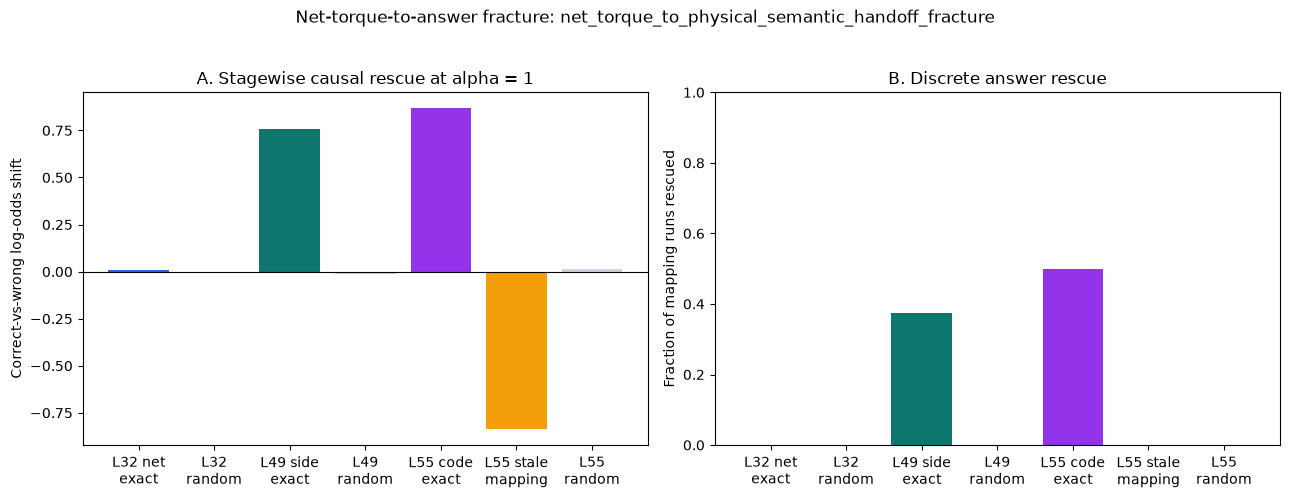

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_nettorque_to_answer_fracture_rescue_v1/analysis/figures/stagewise_fracture_rescue.png
Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_nettorque_to_answer_fracture_rescue_v1/analysis/RESULT_CARD.md
RUN_COMPLETE: /content/drive/MyDrive/VisualTorque/results/qwen27b_nettorque_to_answer_fracture_rescue_v1/RUN_COMPLETE.json


In [18]:
%%cell_progress 17/17 Save the figure, result card, and completion manifest
cell_stage('Writing paper-facing artifacts')
import matplotlib.pyplot as plt

condition_order = [
    'l32_net_exact', 'l32_net_random',
    'l49_semantic_exact', 'l49_semantic_random',
    'l55_code_exact', 'l55_code_stale', 'l55_code_random',
]
labels = {
    'l32_net_exact': 'L32 net\nexact', 'l32_net_random': 'L32\nrandom',
    'l49_semantic_exact': 'L49 side\nexact',
    'l49_semantic_random': 'L49\nrandom',
    'l55_code_exact': 'L55 code\nexact', 'l55_code_stale': 'L55 stale\nmapping',
    'l55_code_random': 'L55\nrandom',
}
primary_plot = primary.groupby('condition').agg(
    shift=('margin_shift', 'mean'), rescue=('rescued', 'mean')
).reindex(condition_order)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = ['#2563EB', '#CBD5E1', '#0F766E', '#CBD5E1', '#9333EA', '#F59E0B', '#CBD5E1']
axes[0].bar(range(len(primary_plot)), primary_plot['shift'], color=colors)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_xticks(range(len(primary_plot)), [labels[x] for x in primary_plot.index])
axes[0].set_ylabel('Correct-vs-wrong log-odds shift')
axes[0].set_title('A. Stagewise causal rescue at alpha = 1')
axes[1].bar(range(len(primary_plot)), primary_plot['rescue'], color=colors)
axes[1].set_xticks(range(len(primary_plot)), [labels[x] for x in primary_plot.index])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Fraction of mapping runs rescued')
axes[1].set_title('B. Discrete answer rescue')
fig.suptitle(f'Net-torque-to-answer fracture: {PRIMARY_DECISION}', y=1.03)
fig.tight_layout()
figure_path = FIGURE_DIR / 'stagewise_fracture_rescue.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()

def interval(metric):
    row = test_frame.set_index('metric').loc[metric]
    return f"{row['estimate']:.4f} [{row['ci_low']:.4f}, {row['ci_high']:.4f}]"

lines = [
    '# Net-Torque-to-Answer Fracture Rescue', '',
    f'**Primary decision:** `{PRIMARY_DECISION}`', '',
    '## What was tested', '',
    (
        f'{len(runtime_manifest)} previously frozen Qwen-27B outcome errors '
        'already had the correct net-torque sign in both a direct net-torque '
        'question and a held-out linear readout. Each physical scene remained '
        'wrong after the A/B/C labels assigned to the two sides were swapped.'
    ), '',
    'The same wrong scene was then moved at three preselected locations: the '
    'L32 net-torque direction, the L49 physical left/right direction, and the '
    'L55 prompt-specific answer-code direction. Random, reversed-physics, and '
    'stale-label controls had matched vector length.', '',
    '## Primary effects (alpha = 1)', '',
    f"- L32 exact minus random: {interval('l32_exact_minus_random')}",
    f"- L49 exact minus random: {interval('l49_exact_minus_random')}",
    f"- L55 exact minus stale mapping: {interval('l55_exact_minus_stale')}",
    '', '## Claim boundary', '',
    (
        'A passing stage shows that adding the frozen, physically correct '
        'direction at that location is sufficient to move these particular '
        'errors. It does not prove that every error has the same cause or that '
        'the named variable occupies a pure, one-dimensional representation.'
    ), '',
]
report_path = ANALYSIS_DIR / 'RESULT_CARD.md'
report_path.write_text('\n'.join(lines), encoding='utf-8')

run_complete = {
    'status': 'complete', 'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID, 'revision': MODEL_REVISION,
    'primary_decision': PRIMARY_DECISION,
    'candidate_targets': len(candidate_manifest),
    'runtime_targets': len(runtime_manifest),
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'runtime_lock_sha256': sha256_file(RUNTIME_LOCK_PATH),
    'decision_sha256': sha256_file(ANALYSIS_DIR / 'stagewise_decision.json'),
    'figure': str(figure_path), 'report': str(report_path),
}
write_json_atomic(OUTPUT_ROOT / 'RUN_COMPLETE.json', run_complete)
print('Saved:', figure_path)
print('Saved:', report_path)
print('RUN_COMPLETE:', OUTPUT_ROOT / 'RUN_COMPLETE.json')
